# 04 · Explorar `training_dataset.csv`

Dataset único listo para entrenar: una fila por sesión (participante × tarea) de A11y-CUA.

- **X**: columnas listadas en `feature_spec.json → feature_columns` (interacción + ISO 25022 + contexto).
- **Y**: `y_H1`, `y_H4`, `y_H5`, `y_H6` (0/1; NA = no evaluable), etiquetadas con la rúbrica `configs/rubric.yaml`.
- **fold**: partición agrupada por participante (−1 = agentes).
- Las columnas `dom_*` están solo para análisis: **no usarlas como X** (fuga de información).

In [1]:
import json, pathlib
import pandas as pd
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
D = ROOT / 'data' / 'processed' / 'usab_v2' / 'training'
pd.set_option('display.max_columns', 120); pd.set_option('display.width', 200)

df = pd.read_csv(D / 'training_dataset.csv')
spec = json.load(open(D / 'feature_spec.json', encoding='utf-8'))
print(df.shape)
df.head()

(353, 96)


,session_id,participant_id,task_id,source,fold,user_group,assistive_tech_participant,is_human,include_main,label_status,task_title,url_domain,y_H1,y_H4,y_H5,y_H6,y_any_H1,y_any_H4,y_any_H5,y_any_H6,y_rate_H1,y_rate_H4,y_rate_H5,y_rate_H6,y_sev_H1,y_sev_H4,y_sev_H5,y_sev_H6,pages_assessed_H1,pages_assessed_H4,pages_assessed_H5,pages_assessed_H6,n_clicks,n_keys,n_scrolls,n_pages,clicks_per_min,keys_per_min,scrolls_per_min,mouse_distance_px,scroll_distance_px,repeated_click_rate,post_click_latency_s,dead_click_rate,back_nav_rate,correction_key_ratio,input_reentry_rate,long_pause_ratio,scroll_reversal_rate,page_revisit_rate,focus_churn,iso_efficiency_task_time_s,iso_efficiency_actions,iso_effectiveness_task_completion,iso_efficiency_time_based,iso_satisfaction_perceived_ease,ctx_user_group_BLV,ctx_user_group_agent,ctx_user_group_sighted,ctx_assistive_tech_participant_NA,ctx_assistive_tech_participant_none,ctx_assistive_tech_participant_screen_reader,ctx_assistive_tech_participant_unknown,ctx_task_group_Browsing and Web,ctx_task_group_Document Editing,ctx_task_group_Media,ctx_task_group_System Operations,ctx_task_group_Workflow,ctx_familiarity_High,ctx_familiarity_Low,ctx_familiarity_Medium,ctx_difficulty_before_Easy,ctx_difficulty_before_Hard,ctx_difficulty_before_Low,ctx_difficulty_before_Medium,dom_n_elements_mean,dom_max_depth_mean,dom_n_links_mean,dom_n_buttons_mean,dom_n_inputs_mean,dom_n_forms_mean,dom_n_images_mean,dom_status_regions_mean,dom_loading_indicators_mean,dom_button_style_variety_mean,dom_inconsistent_link_text_mean,dom_has_nav_mean,dom_input_constraint_ratio_mean,dom_input_autocomplete_ratio_mean,dom_input_label_ratio_mean,dom_placeholder_only_ratio_mean,dom_img_alt_ratio_mean,dom_has_breadcrumb_mean,dom_has_search_mean,dom_n_headings_mean,dom_pages
0,S02_a11y_cua:BLVU/BLVU1/1,BLVU1,1,S02_a11y_cua,0,BLV,screen_reader,True,True,labeled,Back to the previous webpage,www.target.com,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.333333,0.0,1.0,2.0,3.0,3.0,3.0,1.0,3.0,0.0,58.0,0.0,NaN,0.0,37.130297,0.0,NaN,358.00000,NaN,NaN,NaN,NaN,0.034483,NaN,0.129892,0.000000,NaN,0.017241,93.724,58.0,1.0,0.640178,0.75,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,2933.0,43.333333,124.666667,91.666667,2.333333,2.0,80.333333,6.0,0.0,0.275547,0.024347,0.666667,0.444444,0.888889,0.888889,0.111111,1.0,0.0,1.0,40.333333,3.0
1,S02_a11y_cua:BLVU/BLVU1/10,BLVU1,10,S02_a11y_cua,0,BLV,screen_reader,True,True,labeled,Translating the language of a webpage,www.facebook.com,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.000000,2.0,0.0,2.0,1.0,1.0,1.0,1.0,1.0,0.0,151.0,0.0,NaN,0.0,63.650862,0.0,NaN,0.00000,NaN,NaN,NaN,NaN,0.026490,NaN,0.080147,NaN,NaN,0.013245,142.339,151.0,1.0,0.421529,0.75,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,153.0,18.000000,44.000000,4.000000,2.000000,1.0,2.000000,0.0,0.0,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.5,0.0,0.0,1.000000,1.0
2,S02_a11y_cua:BLVU/BLVU1/11,BLVU1,11,S02_a11y_cua,0,BLV,screen_reader,True,True,labeled,Searching for a service by setting constraints,www.expedia.com,0.0,0.0,NaN,0.0,0.0,1.0,NaN,1.0,0.0,0.2,NaN,0.200000,0.0,3.0,NaN,2.0,5.0,5.0,0.0,5.0,0.0,445.0,0.0,1.0,0.0,53.202618,0.0,NaN,21785.33345,NaN,NaN,NaN,0.0,0.008989,1.0,1.000000,0.431818,0.0,0.274157,501.855,445.0,0.0,0.000000,0.25,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,821.2,32.000000,39.800000,23.400000,3.400000,0.6,13.000000,0.8,13.6,0.631013,0.029033,0.600000,0.114286,0.000000,0.400000,0.000000,1.0,0.6,0.4,10.400000,5.0
3,S02_a11y_cua:BLVU/BLVU1/12,BLVU1,12,S02_a11y_cua,0,BLV,screen_reader,True,True,labeled,Change default search engine,www.google.com,0.0,0.0,NaN,0.0,0.0,0.0,NaN,0.0,0.0,0.0,NaN,0.000000,0.0,1.0,NaN,1.0,2.0,2.0,0.0,2.0,0.0,108.0,0.0,1.0,0.0,51.701440,0.0,NaN,0.00000,NaN,NaN,NaN,0.0,0.092593,NaN,0.000000,NaN,0.0,0.000000,125.335,108.0,1.0,0.478717,0.75,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,

## 1. Estructura: roles de las columnas

In [2]:
roles = {**{c: 'id' for c in spec['id_columns']}, spec['fold_column']: 'fold',
         **{c: 'meta' for c in spec['meta_columns']}, **{c: 'Y' for c in spec['target_columns']},
         **{c: 'Y auxiliar' for c in spec['auxiliary_target_columns']},
         **{c: f'X · {g}' for g, cols in spec['feature_groups'].items() for c in cols},
         **{c: 'excluida (fuga)' for c in spec['excluded_from_X_leakage']}}
pd.Series(roles).value_counts().rename('columnas').to_frame()

,columnas
excluida (fuga),21
X · behavior,19
X · context,19
Y auxiliar,16
meta,7
id,4
Y,4
X · iso_outcome,3
X · iso_process,2
fold,1


In [3]:
info = pd.DataFrame({'rol': pd.Series(roles), 'tipo': df.dtypes.astype(str),
                     'no_nulo_%': (100 * df.notna().mean()).round(1), 'unicos': df.nunique()})
info

,rol,tipo,no_nulo_%,unicos
session_id,id,str,100.0,353
participant_id,id,str,100.0,18
task_id,id,int64,100.0,39
source,id,str,100.0,1
fold,fold,int64,100.0,5
...,...,...,...,...
dom_img_alt_ratio_mean,excluida (fuga),float64,99.4,114
dom_has_breadcrumb_mean,excluida (fuga),float64,100.0,12
dom_has_search_mean,excluida (fuga),float64,100.0,19
dom_n_headings_mean,excluida (fuga),float64,100.0,159


## 2. Muestra principal (humanos) y variables objetivo

In [4]:
main = df[df.include_main]
print(f"{len(main)} sesiones humanas · {main.participant_id.nunique()} participantes")
targets = spec['target_columns']
pd.DataFrame({'etiquetadas': main[targets].notna().sum(),
              'violaciones': main[targets].sum(),
              'prevalencia': main[targets].mean().round(3)})

308 sesiones humanas · 16 participantes


,etiquetadas,violaciones,prevalencia
y_H1,308,104.0,0.338
y_H4,308,56.0,0.182
y_H5,54,33.0,0.611
y_H6,308,101.0,0.328


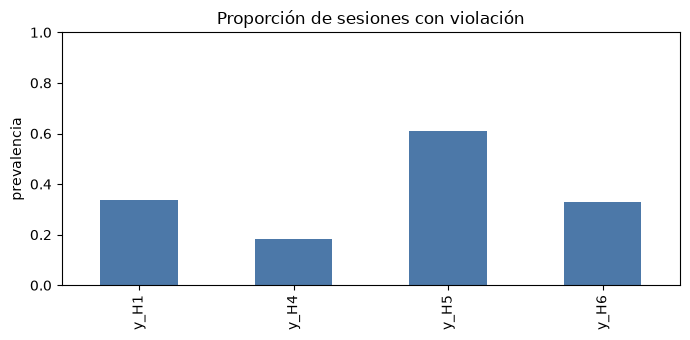

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
main[targets].mean().plot.bar(ax=ax, color='#4C78A8')
ax.set_ylabel('prevalencia'); ax.set_title('Proporción de sesiones con violación'); ax.set_ylim(0, 1)
plt.tight_layout()

In [6]:
# prevalencia por grupo de usuario y por fold
display(main.groupby('user_group')[targets].mean().round(3))
display(main.groupby('fold')[targets].mean().round(3).assign(sesiones=main.groupby('fold').size()))

,y_H1,y_H4,y_H5,y_H6
user_group,,,,
BLV,0.301,0.117,0.643,0.252
sighted,0.379,0.255,0.577,0.414


,y_H1,y_H4,y_H5,y_H6,sesiones
fold,,,,,
0,0.291,0.116,0.615,0.291,86
1,0.321,0.095,0.583,0.250,84
2,0.324,0.284,0.625,0.432,74
3,0.438,0.266,0.615,0.359,64


## 3. Variables X

In [7]:
X = main[spec['feature_columns']]
X.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
n_clicks,308.0,5.026,7.868,0.000,0.000,0.000,7.000,42.000
n_keys,308.0,101.968,113.505,0.000,28.000,60.000,132.250,769.000
n_scrolls,308.0,11.153,62.524,0.000,0.000,0.000,0.000,825.000
n_pages,284.0,1.655,0.929,1.000,1.000,1.000,2.000,8.000
clicks_per_min,308.0,3.555,5.123,0.000,0.000,0.000,6.353,38.022
keys_per_min,308.0,32.731,19.457,0.000,16.620,32.070,46.463,119.033
scrolls_per_min,308.0,5.356,26.165,0.000,0.000,0.000,0.000,323.722
mouse_distance_px,145.0,10346.884,8628.796,946.051,5303.742,7429.745,11672.400,51118.242
scroll_distance_px,308.0,2533.260,7024.409,0.000,0.000,48.000,1852.000,80699.999
repeated_click_rate,145.0,0.027,0.098,0.000,0.000,0.000,0.000,0.810


In [8]:
# cobertura por grupo de variables (NaN = la fuente no lo captura; no se imputa aquí)
pd.DataFrame({g: [len(c), round(100 * main[c].notna().mean().mean(), 1)] for g, c in spec['feature_groups'].items()},
             index=['variables', 'cobertura_%']).T

,variables,cobertura_%
behavior,19.0,81.9
iso_process,2.0,100.0
iso_outcome,3.0,100.0
context,19.0,100.0


In [9]:
# medianas de los indicadores conductuales según haya o no violación
beh = spec['feature_groups']['behavior']
h = 'y_H1'   # cambie a y_H4 / y_H5 / y_H6
main.groupby(h)[beh].median().T.round(3)

y_H1,0.0,1.0
n_clicks,0.000,2.500
n_keys,62.000,50.500
n_scrolls,0.000,0.000
n_pages,1.000,1.000
clicks_per_min,0.000,1.552
keys_per_min,30.658,34.996
scrolls_per_min,0.000,0.000
mouse_distance_px,7921.847,6635.370
scroll_distance_px,0.000,229.667
repeated_click_rate,0.000,0.000


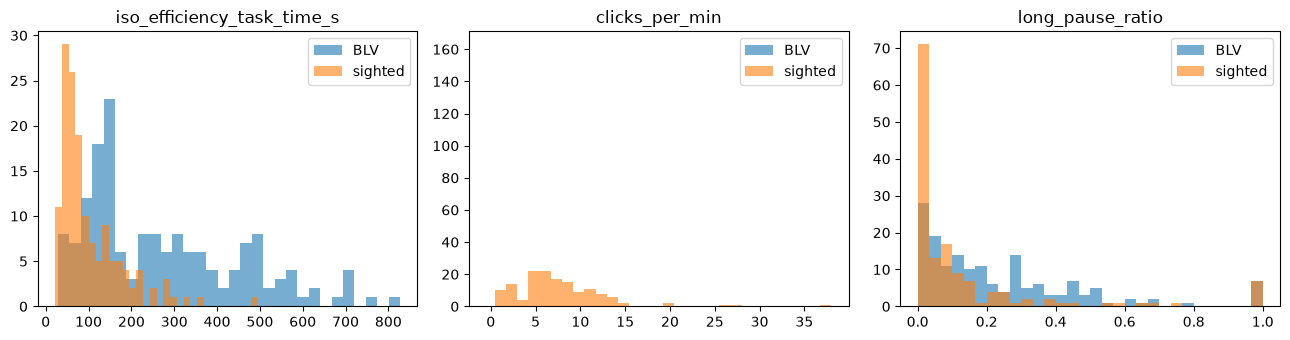

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ['iso_efficiency_task_time_s', 'clicks_per_min', 'long_pause_ratio']):
    for g, d in main.groupby('user_group'):
        ax.hist(d[col].dropna(), bins=30, alpha=0.6, label=g)
    ax.set_title(col); ax.legend()
plt.tight_layout()

## 4. Matriz lista para entrenar (ejemplo)

In [11]:
h = 'y_H1'
data = main[main[h].notna()]
X, y, folds = data[spec['feature_columns']], data[h].astype(int), data[spec['fold_column']]
print('X:', X.shape, '· y positivos:', int(y.sum()), '· folds:', sorted(folds.unique()))
for k in sorted(folds.unique()):
    tr, te = folds != k, folds == k
    print(f'fold {k}: train={tr.sum()} test={te.sum()} prevalencia test={y[te].mean():.2f}')

X: (308, 43) · y positivos: 104 · folds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
fold 0: train=222 test=86 prevalencia test=0.29
fold 1: train=224 test=84 prevalencia test=0.32
fold 2: train=234 test=74 prevalencia test=0.32
fold 3: train=244 test=64 prevalencia test=0.44


## 5. Notas del `feature_spec.json`

In [12]:
for n in spec['notes']: print('-', n)

- No hay imputación: ajústela dentro de cada fold de entrenamiento.
- Las columnas dom_* están en el archivo solo para análisis: NO deben usarse como X (Y proviene del mismo HTML).
- y_H* = mitad o más de las páginas evaluables violan; y_any_H* = alguna página; y_rate_H* = proporción.
- iso_outcome (éxito, facilidad percibida) son resultados de la tarea: pruebe el modelo con y sin ellos.
- Muestra principal: include_main == True (humanos). Agentes con fold = -1.
- Evalúe con validación cruzada agrupada por participant_id usando la columna fold.
